In [39]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

### Import libraries

In [40]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

from pathlib import Path

project_root = Path.cwd().resolve()
for candidate_root in [project_root, *project_root.parents]:
    if (candidate_root / "visualizations").exists() or (candidate_root / "DATA").exists() or (candidate_root / "requirements.txt").exists():
        project_root = candidate_root
        break

visualizations_dir = project_root / "visualizations"
visualizations_dir.mkdir(exist_ok=True, parents=True)


### Load dataset

In [41]:
from pathlib import Path

project_root = Path.cwd().resolve()
data_path = None
for candidate_root in [project_root, *project_root.parents]:
    candidate = candidate_root / "DATA" / "full_grouped.csv"
    if candidate.exists():
        data_path = candidate
        break

if data_path is None:
    raise FileNotFoundError("Could not find DATA/full_grouped.csv from the current working directory.")

for item in sorted(data_path.parent.iterdir()):
    print(item)


D:\project\DS\COVID-19-Exploratory-Data-Analysis\DATA\full_grouped.csv


In [42]:
from pathlib import Path

project_root = Path.cwd().resolve()
data_path = None
for candidate_root in [project_root, *project_root.parents]:
    candidate = candidate_root / "DATA" / "full_grouped.csv"
    if candidate.exists():
        data_path = candidate
        break

if data_path is None:
    raise FileNotFoundError("Could not find DATA/full_grouped.csv from the current working directory.")

df = pd.read_csv(data_path)


## Initial data exploration

In [43]:
# first  five rows
df.head()

,Date,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,WHO Region
0,2020-01-22,Afghanistan,0,0,0,0,0,0,0,Eastern Mediterranean
1,2020-01-22,Albania,0,0,0,0,0,0,0,Europe
2,2020-01-22,Algeria,0,0,0,0,0,0,0,Africa
3,2020-01-22,Andorra,0,0,0,0,0,0,0,Europe
4,2020-01-22,Angola,0,0,0,0,0,0,0,Africa


In [44]:
# Dataset dimensions
df.shape

(35156, 10)

In [45]:
# dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35156 entries, 0 to 35155
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Date            35156 non-null  str  
 1   Country/Region  35156 non-null  str  
 2   Confirmed       35156 non-null  int64
 3   Deaths          35156 non-null  int64
 4   Recovered       35156 non-null  int64
 5   Active          35156 non-null  int64
 6   New cases       35156 non-null  int64
 7   New deaths      35156 non-null  int64
 8   New recovered   35156 non-null  int64
 9   WHO Region      35156 non-null  str  
dtypes: int64(7), str(3)
memory usage: 3.6 MB


In [46]:
# statistical summary
df.describe()

,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered
count,3.515600e+04,35156.000000,3.515600e+04,3.515600e+04,35156.00000,35156.000000,35156.000000
mean,2.356663e+04,1234.068239,1.104813e+04,1.128443e+04,469.36375,18.603339,269.315593
std,1.499818e+05,7437.238354,6.454640e+04,8.997149e+04,3005.86754,115.706351,2068.063852
min,0.000000e+00,0.000000,0.000000e+00,-2.000000e+00,0.00000,-1918.000000,-16298.000000
25%,1.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.00000,0.000000,0.000000
50%,2.500000e+02,4.000000,3.300000e+01,8.500000e+01,2.00000,0.000000,0.000000
75%,3.640250e+03,78.250000,1.286250e+03,1.454000e+03,75.00000,1.000000,20.000000
max,4.290259e+06,148011.000000,1.846641e+06,2.816444e+06,77255.00000,3887.000000,140050.000000


In [47]:
# coloumns names
df.columns

Index(['Date', 'Country/Region', 'Confirmed', 'Deaths', 'Recovered', 'Active',
       'New cases', 'New deaths', 'New recovered', 'WHO Region'],
      dtype='str')

## Data Quality Checks

In [48]:
# Check missing values
df.isnull().sum()

Date              0
Country/Region    0
Confirmed         0
Deaths            0
Recovered         0
Active            0
New cases         0
New deaths        0
New recovered     0
WHO Region        0
dtype: int64

In [49]:
(df.isnull().sum() / len(df)) * 100

Date              0.0
Country/Region    0.0
Confirmed         0.0
Deaths            0.0
Recovered         0.0
Active            0.0
New cases         0.0
New deaths        0.0
New recovered     0.0
WHO Region        0.0
dtype: float64

In [50]:
# Check duplicate records
df.duplicated().sum()

np.int64(0)

In [51]:
# Convert Date into datetime
df['Date'] = pd.to_datetime(df['Date'])

df['Date'].dtype

dtype('<M8[us]')

In [52]:
# Check date range
print("Starting Date:", df['Date'].min())
print("Ending Date:", df['Date'].max())

Starting Date: 2020-01-22 00:00:00
Ending Date: 2020-07-27 00:00:00


In [53]:
# Check unique countries and regions
print("Total Countries:", df['Country/Region'].nunique())

print("WHO Regions:")
print(df['WHO Region'].unique())

Total Countries: 187
WHO Regions:
<ArrowStringArray>
['Eastern Mediterranean',                'Europe',                'Africa',
              'Americas',       'Western Pacific',       'South-East Asia']
Length: 6, dtype: str


In [54]:
# Investigate negative values
numeric_cols = df.select_dtypes(include=np.number).columns

(df[numeric_cols] < 0).sum()

Confirmed         0
Deaths            0
Recovered         0
Active            2
New cases         0
New deaths       38
New recovered    77
dtype: int64

## Feature Engineering

In [55]:
# Extract year, month and day
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['Month_Name'] = df['Date'].dt.month_name()

df.head()

,Date,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,WHO Region,Year,Month,Day,Month_Name
0,2020-01-22,Afghanistan,0,0,0,0,0,0,0,Eastern Mediterranean,2020,1,22,January
1,2020-01-22,Albania,0,0,0,0,0,0,0,Europe,2020,1,22,January
2,2020-01-22,Algeria,0,0,0,0,0,0,0,Africa,2020,1,22,January
3,2020-01-22,Andorra,0,0,0,0,0,0,0,Europe,2020,1,22,January
4,2020-01-22,Angola,0,0,0,0,0,0,0,Africa,2020,1,22,January


In [56]:
# Check the number of records per date
df.groupby('Date').size()

Date
2020-01-22    187
2020-01-23    187
2020-01-24    187
2020-01-25    187
2020-01-26    187
             ... 
2020-07-23    187
2020-07-24    187
2020-07-25    187
2020-07-26    187
2020-07-27    187
Length: 188, dtype: int64

In [57]:
# Check country-wise latest statistics
latest_date = df['Date'].max()

latest_data = df[df['Date'] == latest_date]

latest_data.head()

,Date,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,WHO Region,Year,Month,Day,Month_Name
34969,2020-07-27,Afghanistan,36263,1269,25198,9796,106,10,18,Eastern Mediterranean,2020,7,27,July
34970,2020-07-27,Albania,4880,144,2745,1991,117,6,63,Europe,2020,7,27,July
34971,2020-07-27,Algeria,27973,1163,18837,7973,616,8,749,Africa,2020,7,27,July
34972,2020-07-27,Andorra,907,52,803,52,10,0,0,Europe,2020,7,27,July
34973,2020-07-27,Angola,950,41,242,667,18,1,0,Africa,2020,7,27,July


In [58]:
# identify the top 10 countries by confirmed cases:
top_countries = latest_data.sort_values(
    by='Confirmed',
    ascending=False
).head(10)

top_countries[['Country/Region', 'Confirmed', 'Deaths', 'Recovered']]

,Country/Region,Confirmed,Deaths,Recovered
35142,US,4290259,148011,1325804
34992,Brazil,2442375,87618,1846641
35048,India,1480073,33408,951166
35107,Russia,816680,13334,602249
35123,South Africa,452529,7067,274925
35080,Mexico,395489,44022,303810
35101,Peru,389717,18418,272547
35004,Chile,347923,9187,319954
35146,United Kingdom,301708,45844,1437
35050,Iran,293606,15912,255144


## visualization:

In [59]:
# First visualization: Global COVID-19 trend

global_trend = df.groupby('Date')[[
    'Confirmed',
    'Deaths',
    'Recovered',
    'Active'
]].sum().reset_index()

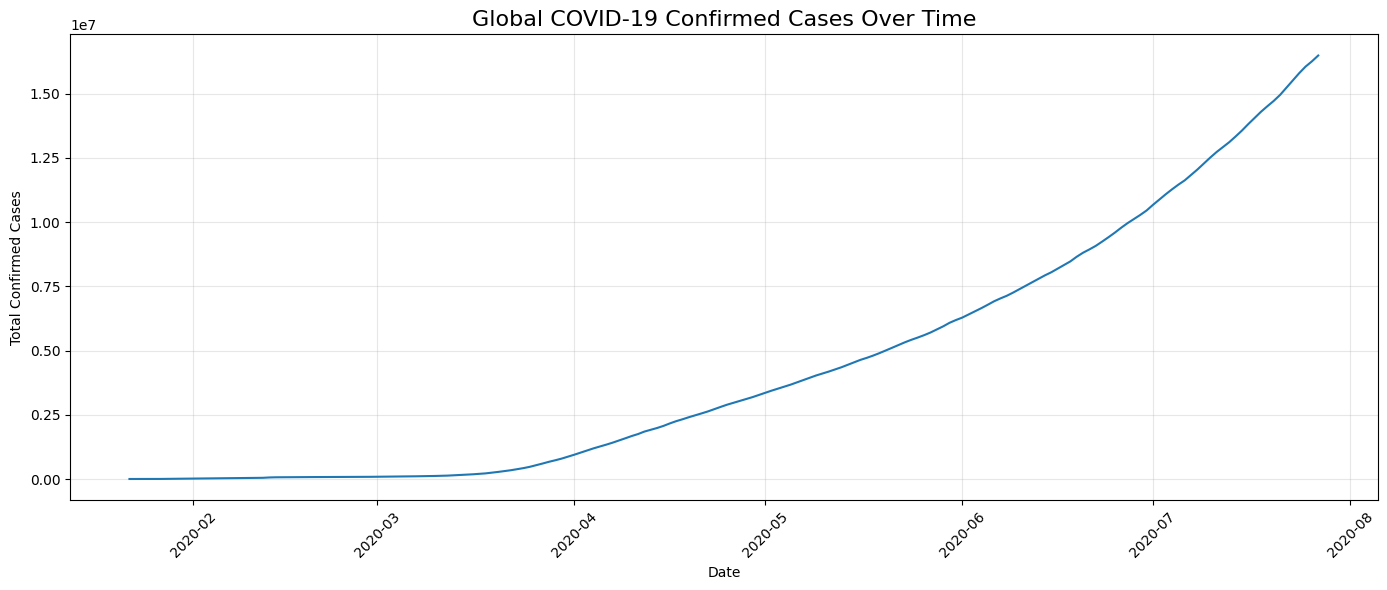

In [60]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=global_trend,
    x='Date',
    y='Confirmed'
)

plt.title('Global COVID-19 Confirmed Cases Over Time',
          fontsize=16)

plt.xlabel('Date')
plt.ylabel('Total Confirmed Cases')

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(visualizations_dir / 'global_trend.png', dpi=300, bbox_inches='tight')
plt.show()

### Compare Top 5 Countries by COVID-19 Cases

In [61]:
# Get the latest country-wise data

latest_date = df['Date'].max()

latest_data = df[df['Date'] == latest_date].copy()

top_5 = latest_data.nlargest(5, 'Confirmed')

top_5[['Country/Region', 'Confirmed', 'Deaths', 'Recovered']]

,Country/Region,Confirmed,Deaths,Recovered
35142,US,4290259,148011,1325804
34992,Brazil,2442375,87618,1846641
35048,India,1480073,33408,951166
35107,Russia,816680,13334,602249
35123,South Africa,452529,7067,274925


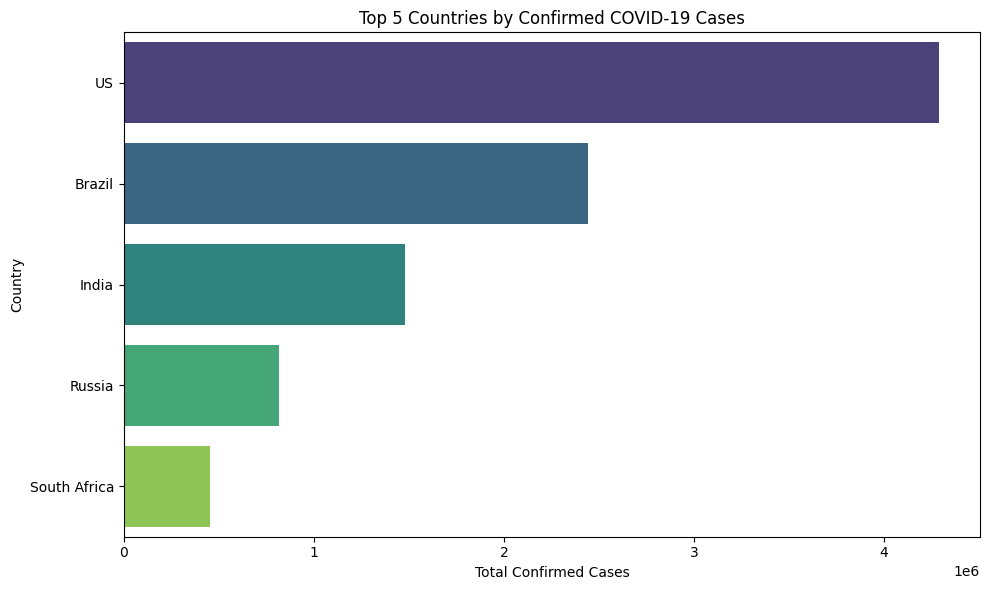

In [62]:
# Create a bar chart using Seaborn
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_5,
    x='Confirmed',
    y='Country/Region',
    hue='Country/Region',
    palette='viridis',
    legend=False
)

plt.title('Top 5 Countries by Confirmed COVID-19 Cases')
plt.xlabel('Total Confirmed Cases')
plt.ylabel('Country')

plt.tight_layout()
plt.savefig(visualizations_dir / 'confirmed_CAse.png', dpi=300, bbox_inches='tight')
plt.show()

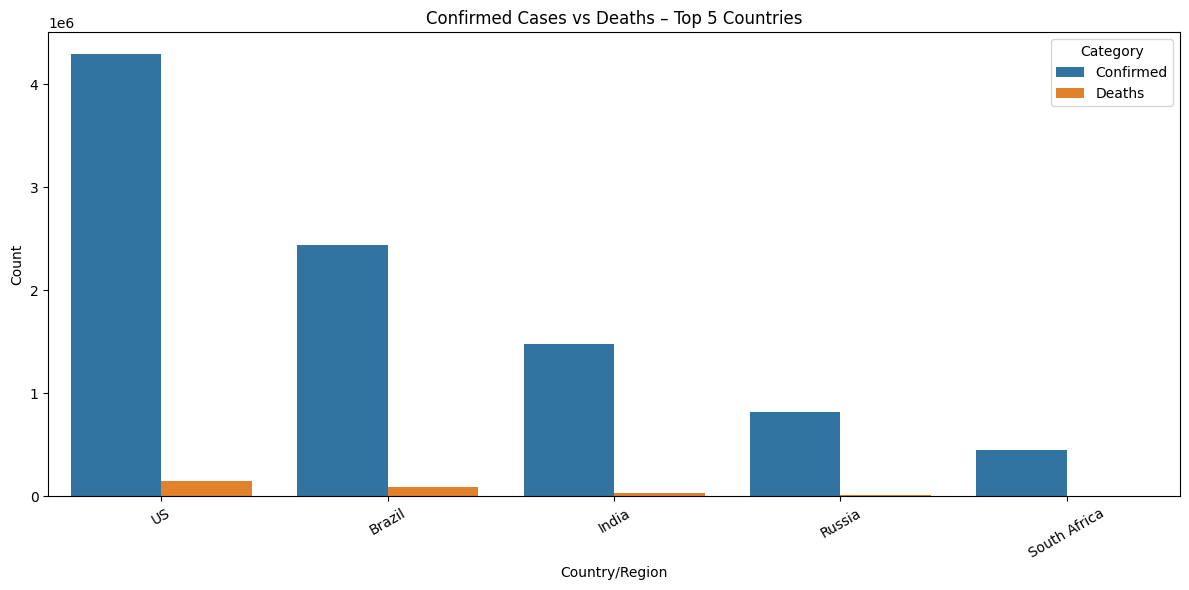

In [63]:
# Compare cases and deaths

top_5_melted = top_5.melt(
    id_vars='Country/Region',
    value_vars=['Confirmed', 'Deaths'],
    var_name='Category',
    value_name='Count'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_5_melted,
    x='Country/Region',
    y='Count',
    hue='Category'
)

plt.title('Confirmed Cases vs Deaths – Top 5 Countries')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(visualizations_dir / 'case_vs_death.png', dpi=300, bbox_inches='tight')
plt.show()

In [64]:
# Death rate comparison

top_5 = top_5.copy()

top_5['Death Rate (%)'] = (
    top_5['Deaths'] / top_5['Confirmed'].replace(0, np.nan)
) * 100

top_5[['Country/Region', 'Confirmed', 'Deaths', 'Death Rate (%)']]

,Country/Region,Confirmed,Deaths,Death Rate (%)
35142,US,4290259,148011,3.449932
34992,Brazil,2442375,87618,3.587410
35048,India,1480073,33408,2.257186
35107,Russia,816680,13334,1.632708
35123,South Africa,452529,7067,1.561668


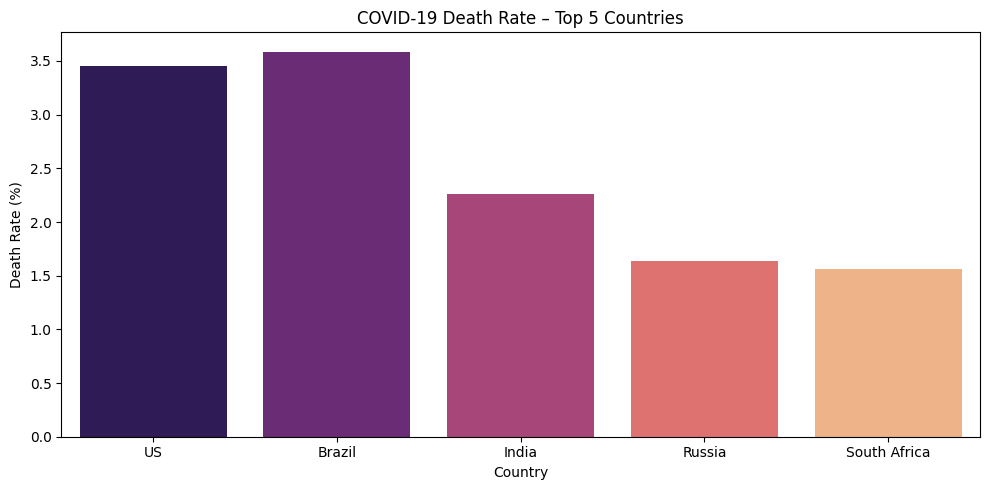

In [65]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_5,
    x='Country/Region',
    y='Death Rate (%)',
    hue='Country/Region',
    legend=False,
    palette='magma'
)

plt.title('COVID-19 Death Rate – Top 5 Countries')
plt.ylabel('Death Rate (%)')
plt.xlabel('Country')

plt.tight_layout()
plt.savefig(visualizations_dir / 'death_Rate.png', dpi=300, bbox_inches='tight')
plt.show()

## Correlation Heatmap

In [66]:
# Calculate correlation

numeric_data = df.select_dtypes(include=np.number)

correlation = numeric_data.corr()

correlation

,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Year,Month,Day
Confirmed,1.000000,0.912016,0.894418,0.949940,0.893966,0.602815,0.675623,NaN,0.155134,0.006847
Deaths,0.912016,1.000000,0.761093,0.891647,0.767812,0.630283,0.551870,NaN,0.149233,0.004186
Recovered,0.894418,0.761093,1.000000,0.710665,0.808816,0.515154,0.761926,NaN,0.188124,0.009982
Active,0.949940,0.891647,0.710665,1.000000,0.846513,0.583212,0.534027,NaN,0.111310,0.003907
New cases,0.893966,0.767812,0.808816,0.846513,1.000000,0.733583,0.725761,NaN,0.125090,0.003412
New deaths,0.602815,0.630283,0.515154,0.583212,0.733583,1.000000,0.503319,NaN,0.082928,-0.002214
New recovered,0.675623,0.551870,0.761926,0.534027,0.725761,0.503319,1.000000,NaN,0.126631,0.000645
Year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month,0.155134,0.149233,0.188124,0.111310,0.125090,0.082928,0.126631,NaN,1.000000,-0.149682
Day,0.006847,0.004186,0.009982,0.003907,0.003412,-0.002214,0.000645,NaN,-0.149682,1.000000


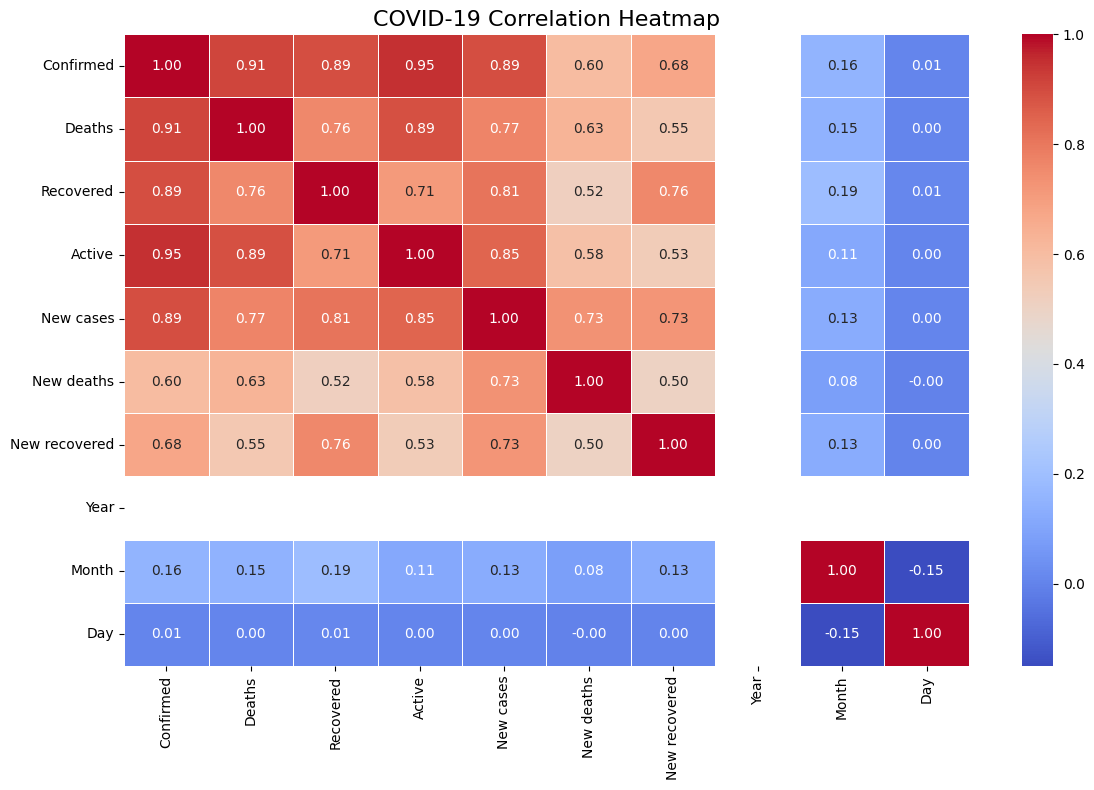

In [67]:
# Create heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('COVID-19 Correlation Heatmap', fontsize=16)

plt.tight_layout()
plt.savefig(visualizations_dir / 'heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

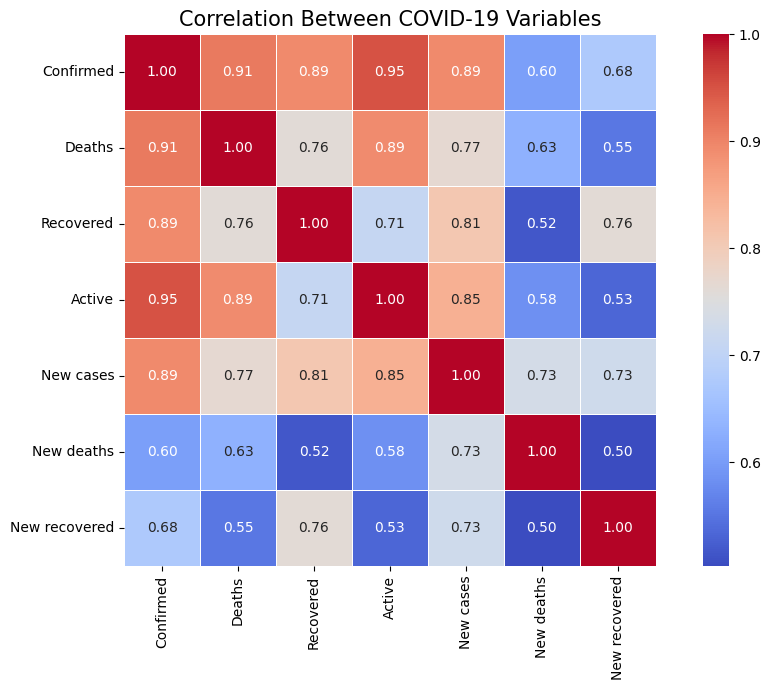

In [68]:
# Improve the heatmap1

features = [
    'Confirmed',
    'Deaths',
    'Recovered',
    'Active',
    'New cases',
    'New deaths',
    'New recovered'
]

corr_matrix = df[features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title('Correlation Between COVID-19 Variables',
          fontsize=15)

plt.tight_layout()
plt.savefig(visualizations_dir / 'improve_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

## Scatter Plot

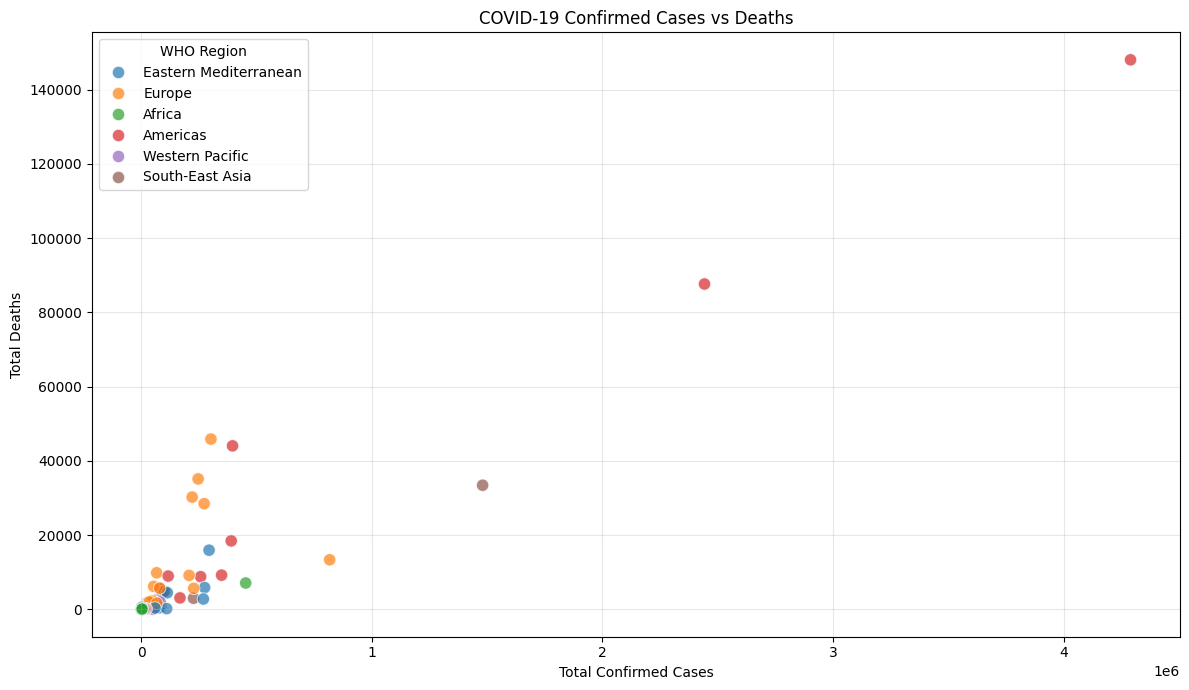

In [69]:
# Create scatter plot

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=latest_data,
    x='Confirmed',
    y='Deaths',
    hue='WHO Region',
    alpha=0.7,
    s=80
)

plt.title('COVID-19 Confirmed Cases vs Deaths')
plt.xlabel('Total Confirmed Cases')
plt.ylabel('Total Deaths')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(visualizations_dir / 'caseVSdeath_scatterplot.png', dpi=300, bbox_inches='tight')
plt.show()

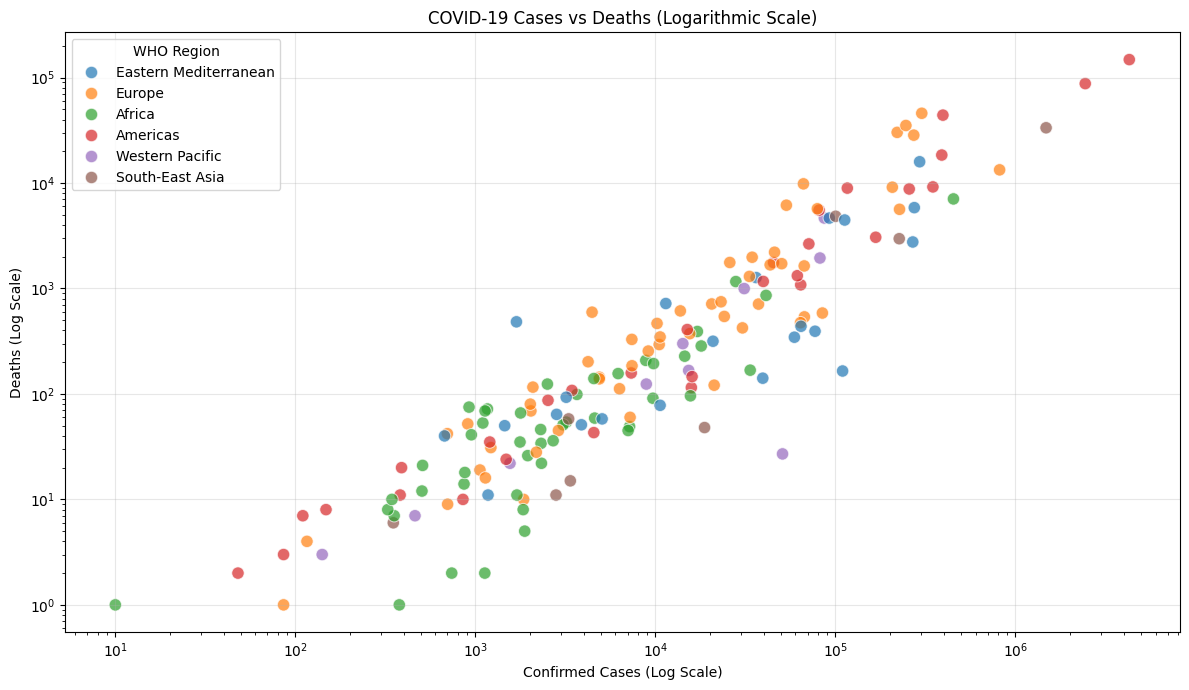

In [70]:
# Improve the visualization using logarithmic scale

positive_data = latest_data[
    (latest_data['Confirmed'] > 0) &
    (latest_data['Deaths'] > 0)
]

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=positive_data,
    x='Confirmed',
    y='Deaths',
    hue='WHO Region',
    alpha=0.7,
    s=80
)

plt.xscale('log')
plt.yscale('log')

plt.title('COVID-19 Cases vs Deaths (Logarithmic Scale)')
plt.xlabel('Confirmed Cases (Log Scale)')
plt.ylabel('Deaths (Log Scale)')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(visualizations_dir / 'caseVSdeath_improved_Scatterplot.png', dpi=300, bbox_inches='tight')
plt.show()

## Key Findings and Insights

**Dataset:** COVID-19 Global Data (22 January – 27 July 2020)

### 1. Global COVID-19 Trends
The cumulative number of confirmed COVID-19 cases increased substantially during the observation period.

### 2. Top Five Countries
The United States recorded the highest confirmed cases, followed by Brazil, India, Russia, and South Africa as of 27 July 2020.

### 3. Confirmed Cases and Deaths
The scatter plot indicates a positive relationship between confirmed COVID-19 cases and reported deaths across countries.

### 4. Correlation Analysis
- Confirmed and Active cases showed a strong positive correlation (0.95).
- Confirmed cases and Deaths were strongly correlated (0.91).
- New cases and New deaths showed a positive correlation (0.73).

### 5. Data Quality
- No missing values were found.
- No duplicate rows were detected.
- Negative values were identified in Active, New deaths, and New recovered, potentially reflecting reporting adjustments.

### Conclusion
The analysis demonstrates how Matplotlib and Seaborn can be used to explore historical COVID-19 patterns, compare countries, and identify statistical relationships. Correlation does not imply causation, and the findings are limited to the dataset's historical reporting period.